In [60]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

dry_bean = fetch_ucirepo(id=602)
x = dry_bean.data.features
y = dry_bean.data.targets['Class']

beans = pd.DataFrame(x)
beans['Classes'] = y
beans[:5]

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Classes
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [61]:
print(f"Dataset dimension: {x.shape}, {y.shape}")

Dataset dimension: (13611, 16), (13611,)


In [62]:
print(f"Missing values: {x.isnull().sum().sum()}")
print(f"Duplicates: {x.duplicated().sum()}")

Missing values: 0
Duplicates: 68


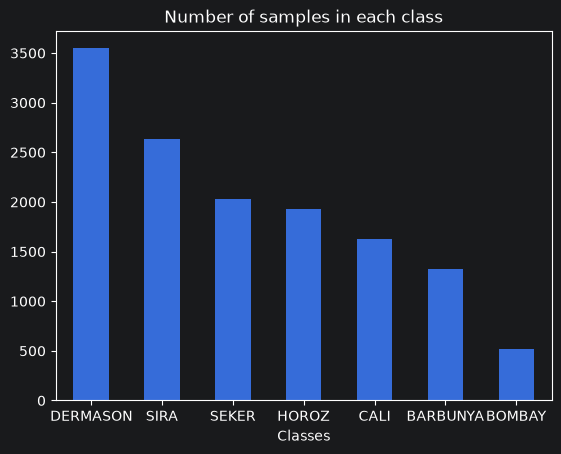

In [63]:
class_counts = beans["Classes"].value_counts()

class_counts.plot(kind = 'bar')
plt.title("Number of samples in each class")
plt.xticks(rotation = 0)
plt.show()

In [64]:
x.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860154,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


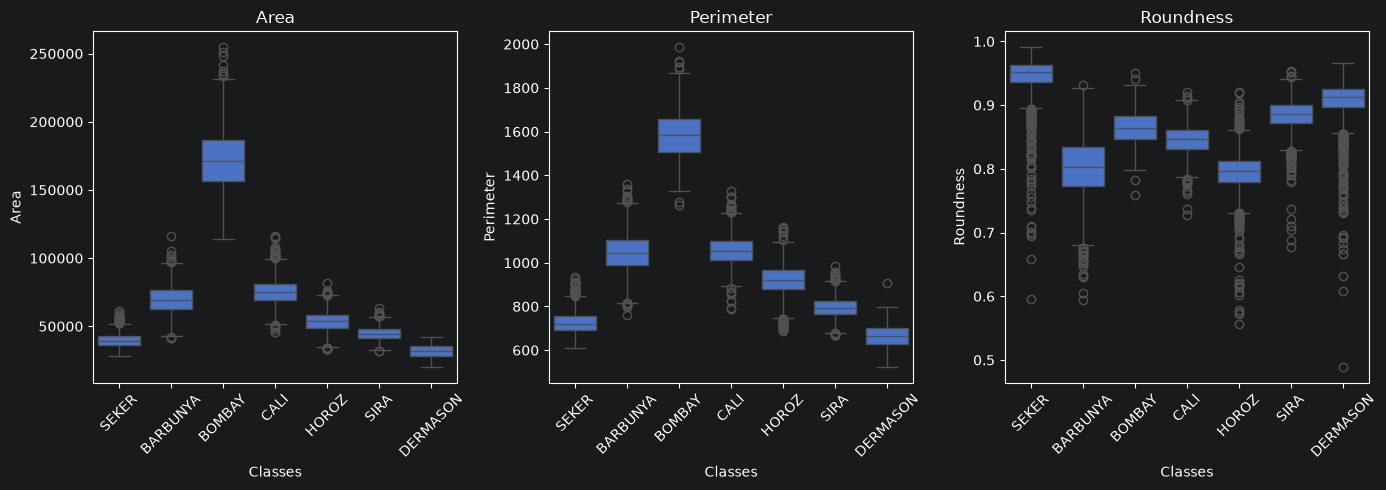

In [65]:
features = ['Area', 'Perimeter', 'Roundness']
fig, axes = plt.subplots(1, len(features), figsize=(14, 5))
for ax, feature in zip(axes, features):
    sns.boxplot(data=beans, x="Classes", y=feature, ax=ax)
    ax.set_title(feature)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [66]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split

class_labels = sorted(y.unique())
print(class_labels)

x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.4, random_state=36, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=36, stratify=y_temp)
mlp1 = MLPClassifier(hidden_layer_sizes=(25, 15, 10, 5), random_state=36)

print(x_train.shape, x_val.shape, x_test.shape)

['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
(8166, 16) (2722, 16) (2723, 16)


In [67]:
def standartization(n, u, q):
    return (n-u)/q

u_train = x_train.mean()
q_train = x_train.std(ddof=0)

x_train_scal = standartization(x_train, u_train, q_train)
x_val_scal = standartization(x_val, u_train, q_train)
x_test_scal = standartization(x_test, u_train, q_train)

Accuracy: 0.26


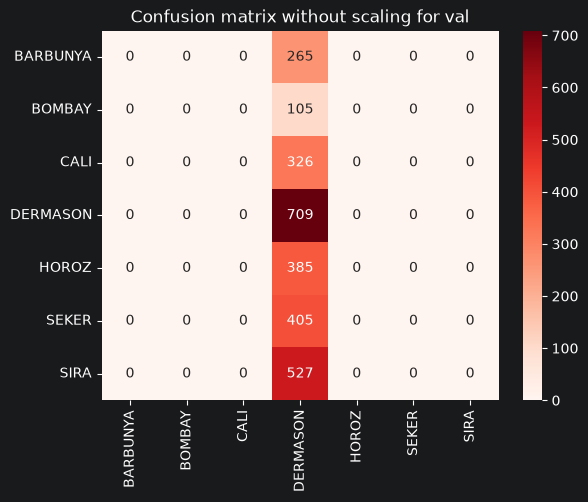

In [68]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, log_loss

mlp1.fit(x_train, y_train)
pred = mlp1.predict(x_val)

accuracy = accuracy_score(y_val, pred)
print(f"Accuracy: {round(accuracy, 2)}")

matrix = confusion_matrix(y_val, pred, labels=mlp1.classes_)
sns.heatmap(matrix, annot=True, fmt="d", cmap="Reds", xticklabels=mlp1.classes_, yticklabels=mlp1.classes_)
plt.title("Confusion matrix without scaling for val")
plt.show()


In [69]:
print(classification_report(y_val, pred, zero_division=0))

              precision    recall  f1-score   support

    BARBUNYA       0.00      0.00      0.00       265
      BOMBAY       0.00      0.00      0.00       105
        CALI       0.00      0.00      0.00       326
    DERMASON       0.26      1.00      0.41       709
       HOROZ       0.00      0.00      0.00       385
       SEKER       0.00      0.00      0.00       405
        SIRA       0.00      0.00      0.00       527

    accuracy                           0.26      2722
   macro avg       0.04      0.14      0.06      2722
weighted avg       0.07      0.26      0.11      2722



Accuracy: 0.93


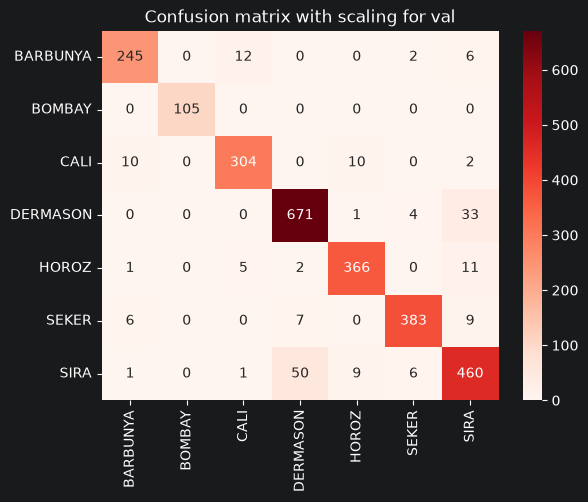

In [70]:
mlp2 = MLPClassifier(hidden_layer_sizes=(25, 15, 10, 5), random_state=36, max_iter=300)
mlp2.fit(x_train_scal, y_train)
pred_scal = mlp2.predict(x_val_scal)

accuracy_scal = accuracy_score(y_val, pred_scal)
print(f"Accuracy: {round(accuracy_scal, 2)}")

matrix = confusion_matrix(y_val, pred_scal, labels=mlp2.classes_)
sns.heatmap(matrix, annot=True, fmt="d", cmap="Reds", xticklabels=mlp2.classes_, yticklabels=mlp2.classes_)
plt.title("Confusion matrix with scaling for val")
plt.show()

In [71]:
print(classification_report(y_val, pred_scal, zero_division=0))

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.92      0.93       265
      BOMBAY       1.00      1.00      1.00       105
        CALI       0.94      0.93      0.94       326
    DERMASON       0.92      0.95      0.93       709
       HOROZ       0.95      0.95      0.95       385
       SEKER       0.97      0.95      0.96       405
        SIRA       0.88      0.87      0.88       527

    accuracy                           0.93      2722
   macro avg       0.94      0.94      0.94      2722
weighted avg       0.93      0.93      0.93      2722



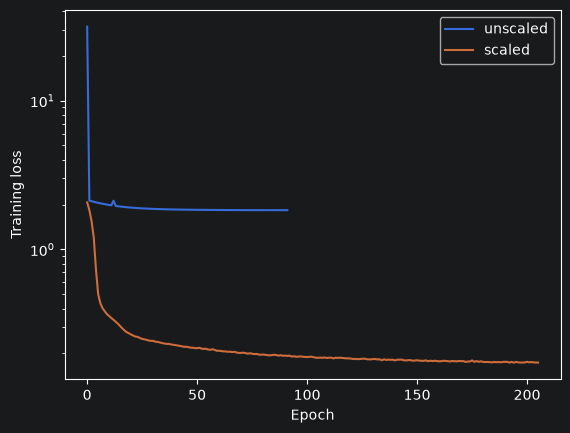

In [73]:
plt.plot(mlp1.loss_curve_, label="unscaled")
plt.plot(mlp2.loss_curve_, label='scaled')
plt.xlabel('Epoch')
plt.yscale("log")
plt.ylabel('Training loss')
plt.legend()
plt.show()

In [74]:
val_loss = log_loss(y_val, mlp1.predict_proba(x_val), labels=mlp1.classes_)
val_loss_scaled = log_loss(y_val, mlp2.predict_proba(x_val_scal), labels=mlp2.classes_)

print(f"Val loss unscaled: {val_loss:.4f}")
print(f"Val loss scaled:   {val_loss_scaled:.4f}")
print(f"Train loss unscaled: {mlp1.loss_:.4f}, scaled: {mlp2.loss_:.4f}")
print(f"Epochs unscaled: {mlp1.n_iter_}, scaled: {mlp2.n_iter_}")

Val loss unscaled: 1.8353
Val loss scaled:   0.2152
Train loss unscaled: 1.8350, scaled: 0.1733
Epochs unscaled: 92, scaled: 206
